# 9. Instrument check: tuning forks, steel bowl and peak limiter

Recordings made on **28 October 2026** indoors, with the same iPhone 16e and Voice Record Pro (WAV, 48 kHz, 16 bit,
mono, *Voice Processing* disabled, manual gain 0 dB, silence detection disabled):

* **Tuning forks** with a printed frequency: 256 Hz (rectangular section, printed note) and 329.6 Hz (Hohner).
* **Stainless-steel kitchen bowl**, struck on the rim with the rubber-covered hammer used on the stone, with the
  microphone 5 cm and 20 cm from the rim opposite the strike (the first two takes do not have the distance in their
  name). It serves as a reference of a metallic, bell-like resonator and to check that the measured decay depends
  neither on the level nor on the distance.

It is also checked whether the recording chain **limits the peaks** in the recordings of the stone.

**Inputs:** `C.INSTRUMENT_CHECK/*.wav`, WAV files of 19 Oct 2025, `intermediate/strikes_with_acceleration.csv` (02),
`tables/t03_damping_strikes.csv` (03). **Outputs:** `tables/t09_tuning_forks.csv`, `tables/t09_bowl_T60.csv`,
`tables/t09_bowl_interval_sensitivity.csv`, `tables/t09_stone_peaks.csv`, `figures/fig09a_limiter.png`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import glob, datetime as dt
from scipy import signal, stats
from scipy.io import wavfile
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
FS = C.FS

## 9.1 Tuning forks

In each take, 4 s of sound from 0.3 s after the envelope maximum are analysed; the frequency is the maximum of the
spectrum (Hann, zero padding to 2²¹ points) interpolated with a parabola on a logarithmic scale. Takes whose maximum
falls below 200 Hz (handling noise) are discarded.

In [2]:
NOMINAL = {"256Hz": (256.0, "printed (note)"), "329Hz": (329.63, "printed (Hohner, E4)")}
rows = []
for f in sorted(glob.glob(str(C.INSTRUMENT_CHECK / "*Hz.wav"))):
    key = Path(f).stem.split("_")[-1]; nom, label = NOMINAL[key]
    _, x = wavfile.read(f); x = x.astype(float) - x.mean()
    env = np.convolve(np.abs(x), np.ones(4800) / 4800, "same")
    p, _ = signal.find_peaks(env, height=env.max() * 0.2, distance=int(8 * FS))
    for i in p:
        s = x[i + int(0.3 * FS): i + int(4.3 * FS)]
        if len(s) < FS: continue
        N = 2 ** 21; X = np.abs(np.fft.rfft(s * np.hanning(len(s)), N)); fr = np.fft.rfftfreq(N, 1 / FS)
        X[(fr < 150) | (fr > 1500)] = 0; j = int(np.argmax(X))
        y0, y1, y2 = np.log(X[j - 1:j + 2]); f0 = (j + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)) * fr[1]
        if f0 > 200:
            rows.append({"file": Path(f).name, "fork": key, "nominal_Hz": nom, "label": label, "f_Hz": f0})
d = pd.DataFrame(rows)
t = d.groupby(["fork", "nominal_Hz", "label"]).f_Hz.agg(["mean", "std", "size"]).reset_index()
t.columns = ["fork", "nominal_Hz", "label", "f_mean_Hz", "sd_Hz", "takes"]
t["error_pct"] = 100 * (t.f_mean_Hz / t.nominal_Hz - 1)
t.to_csv(C.TABLES / "t09_tuning_forks.csv", index=False)
t.round({"f_mean_Hz": 3, "sd_Hz": 3, "error_pct": 3})

,fork,nominal_Hz,label,f_mean_Hz,sd_Hz,takes,error_pct
0,256Hz,256.00,printed (note),256.23,3.00e-03,4,0.09
1,329Hz,329.63,"printed (Hohner, E4)",329.12,1.70e-02,9,-0.15


**Reading.** The two forks give errors of **+0.09 %** (256 Hz) and **−0.15 %** (329.6 Hz), within the manufacturing
tolerance of a tuning fork and its variation with temperature. Since an error of the phone clock would shift all
frequencies by the same percentage, and the two errors have opposite signs, the sampling rate is correct to better than
~0.1 %.

## 9.2 Steel bowl: decay against level and distance

The strikes are detected in the band > 2 kHz and, for each one, a straight line is fitted to the Hilbert envelope (in
dB) of the main mode of the bowl (352.5 Hz, ±2 Hz filter to separate it from its partner at 358.7 Hz) from 0.5 s to
12 s or to the next strike. The method is that of the stone (Hilbert envelope and straight line in dB), but with a
fixed interval (its choice is checked at the end of this section). If the recording chain is linear, T60 must depend
neither on the strike level (peak) nor on the microphone distance.

In [3]:
def t60(x, i, f0, bw, t1, t2):
    sos = signal.butter(2, [f0 - bw, f0 + bw], "bandpass", fs=FS, output="sos"); seg = x[i:i + int((t2 + 0.5) * FS)]
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, seg))); k = int(0.05 * FS); env = np.convolve(env, np.ones(k) / k, "same")
    tt = np.arange(len(env)) / FS; s = (tt > t1) & (tt < t2); e = 20 * np.log10(env[s]); p = np.polyfit(tt[s], e, 1)
    return -60 / p[0], 1 - np.var(e - np.polyval(p, tt[s])) / np.var(e), e[0] - e[-1]
DIST = {"20261028-232713": "not recorded", "20261028-233038": "not recorded", "20261028-233714": "5 cm",   # the first two takes have no distance in their name
        "20261028-233238": "20 cm", "20261028-233531": "20 cm"}
rows = []
for f in sorted(glob.glob(str(C.INSTRUMENT_CHECK / "2026*.wav"))):
    if "Hz" in f: continue
    _, x = wavfile.read(f); x = x.astype(float)
    b, a = signal.butter(4, 2000 / (FS / 2), "high"); env = np.convolve(np.abs(signal.filtfilt(b, a, x)), np.ones(96) / 96, "same")
    p, _ = signal.find_peaks(env, height=np.median(env) * 30, distance=int(3 * FS))
    for j, i in enumerate(p):
        dur = ((p[j + 1] if j + 1 < len(p) else len(x)) - i) / FS - 0.6
        if dur < 3: continue
        T, r2, decay = t60(x, i, 352.5, 2.0, 0.5, min(dur, 12))
        peak = np.abs(x[i - 2000:i + 2000]).max() / 32768
        if peak < 0.1: continue
        rows.append({"file": Path(f).name, "distance": DIST[Path(f).stem[:15]], "peak": peak, "T60_s": T, "r2": r2, "decay_dB": decay})
bowl = pd.DataFrame(rows); bowl["limited"] = bowl.peak >= 0.90
bowl["Q"] = np.pi * 352.5 * bowl.T60_s / np.log(1000)
bowl.to_csv(C.TABLES / "t09_bowl_T60.csv", index=False)
print(f"{len(bowl)} bowl strikes | T60 = {bowl.T60_s.median():.2f} s (range {bowl.T60_s.min():.1f}–{bowl.T60_s.max():.1f}) | "
      f"Q = {bowl.Q.median():.0f} | median R² {bowl.r2.median():.3f}")
for c in ["distance", "limited"]:
    g = bowl[bowl.distance != "not recorded"].groupby(c).T60_s if c == "distance" else bowl.groupby(c).T60_s
    print(f"by {c}: " + " | ".join(f"{k}: median {v.median():.2f} s (n={len(v)})" for k, v in g),
          f"| Mann–Whitney p = {stats.mannwhitneyu(*[v.values for _, v in g]).pvalue:.2f}")
bowl.round(2)

22 bowl strikes | T60 = 7.74 s (range 6.9–8.4) | Q = 1241 | median R² 0.998
by distance: 20 cm: median 7.78 s (n=8) | 5 cm: median 8.00 s (n=5) | Mann–Whitney p = 0.44
by limited: False: median 7.32 s (n=6) | True: median 7.94 s (n=16) | Mann–Whitney p = 0.05


,file,distance,peak,T60_s,r2,decay_dB,limited,Q
0,20261028-232713.wav,not recorded,0.55,6.92,1.00,31.86,False,1109.37
1,20261028-232713.wav,not recorded,0.92,7.24,0.99,72.07,True,1161.31
2,20261028-232713.wav,not recorded,0.90,6.95,1.00,40.82,True,1113.86
3,20261028-232713.wav,not recorded,0.92,8.13,0.97,74.89,True,1302.93
4,20261028-233038.wav,not recorded,0.86,7.44,1.00,30.06,False,1193.27
5,20261028-233038.wav,not recorded,0.85,7.33,1.00,28.94,False,1174.50
6,20261028-233038.wav,not recorded,0.91,8.17,1.00,39.83,True,1309.19
7,20261028-233038.wav,not recorded,0.91,7.58,1.00,25.89,True,1214.88
8,20261028-233038.wav,not recorded,0.92,8.13,0.99,37.05,True,1303.88
9,20261028-233238_20cm.wav,20 cm,0.73,6.98,1.00,57.50,False,1119.34


### Sensitivity to the fit interval

The bowl fit uses a fixed interval. It starts at **0.5 s** to leave out the attack, the recovery of the peak limiter
(the bowl strikes reach ≈ 0.92 of full scale, section 9.3) and the transient of the very narrow ±2 Hz filter, which
also separates the mode from its partner at 358.7 Hz. It ends at **12 s** (≈ 1.5 T60) **or at the next strike**,
whichever comes first. The fit is repeated moving the start between 0.05 and 1 s and the end between 3 and 12 s (each
end only for the strikes whose free window reaches it).

In [4]:
window = []; sens = []
for f in sorted(glob.glob(str(C.INSTRUMENT_CHECK / "2026*.wav"))):
    if "Hz" in f: continue
    _, x = wavfile.read(f); x = x.astype(float)
    b, a = signal.butter(4, 2000 / (FS / 2), "high"); env = np.convolve(np.abs(signal.filtfilt(b, a, x)), np.ones(96) / 96, "same")
    p, _ = signal.find_peaks(env, height=np.median(env) * 30, distance=int(3 * FS))
    for j, i in enumerate(p):
        dur = ((p[j + 1] if j + 1 < len(p) else len(x)) - i) / FS - 0.6
        if dur < 3 or np.abs(x[i - 2000:i + 2000]).max() / 32768 < 0.1: continue
        window.append(min(dur, 12))
        for t1 in [0.05, 0.1, 0.25, 0.5, 1.0]:
            for t2 in [3, 6, 9, 12]:
                if t2 <= dur:
                    sens.append({"start_s": t1, "end_s": t2, "T60_s": t60(x, i, 352.5, 2.0, t1, t2)[0]})
window = np.array(window); sens = pd.DataFrame(sens)
tab = sens.pivot_table(index="start_s", columns="end_s", values="T60_s", aggfunc="median")
tab.to_csv(C.TABLES / "t09_bowl_interval_sensitivity.csv")
print(f"Fit window used (0.5 s → 12 s or next strike): median {np.median(window):.1f} s, "
      f"{(window >= 12).sum()} of {len(window)} strikes reach 12 s; fitted decay {bowl.decay_dB.min():.0f}–{bowl.decay_dB.max():.0f} dB")
print("Strikes per end:", sens[sens.start_s == 0.5].groupby("end_s").size().to_dict())
start_change = (tab.max() / tab.min() - 1).max()
print(f"Moving the start between 0.05 and 1 s changes the median T60 by at most {100 * start_change:.1f} %")
print("Median T60 (s) by start (rows) and end (columns):"); tab.round(2)

Fit window used (0.5 s → 12 s or next strike): median 9.0 s, 2 of 22 strikes reach 12 s; fitted decay 26–85 dB
Strikes per end: {3: 22, 6: 14, 9: 11, 12: 2}
Moving the start between 0.05 and 1 s changes the median T60 by at most 4.0 %
Median T60 (s) by start (rows) and end (columns):


end_s,3,6,9,12
start_s,,,,
0.05,7.05,7.79,7.71,8.16
0.10,6.98,7.80,7.71,8.17
0.25,7.00,7.85,7.74,8.19
0.50,7.05,7.95,7.77,8.23
1.00,7.17,8.10,7.81,8.29


**Reading.** The start hardly matters: between 0.05 and 1 s the median T60 changes by at most 4 %. The end matters
more: fits ending at 3 s give a T60 of ≈ 7.0 s, 9–14 % lower than those reaching 6–12 s (7.7–8.3 s), which suggests
that the beginning of the decay is somewhat faster than the rest. Each end is computed only with the strikes whose
window reaches it (22, 14, 11 and 2 strikes), so the 12 s column is only indicative. The interval used (median 9 s)
covers almost all of the observable decay; the conclusions (T60 independent of distance and level, Q ≈ 1240) do not
depend on this choice.

## 9.3 Did the phone limit the peaks of the strikes on the stone?

In the bowl recordings, strong strikes always stop at ≈ 0.92 of full scale, without clipped samples: this is the
signature of a **peak limiter** in the iOS audio input (not hard clipping). The peak of each strike on the stone is
measured and it is checked whether the damping of the limited strikes differs.

Peak of the 613 strikes: median 0.922, maximum 0.946; ≥ 0.90 of full scale: 534 (87%)
Q relative to the median of the mode (1102 fits): {False: 0.999, True: 1.0} Mann–Whitney p = 0.52


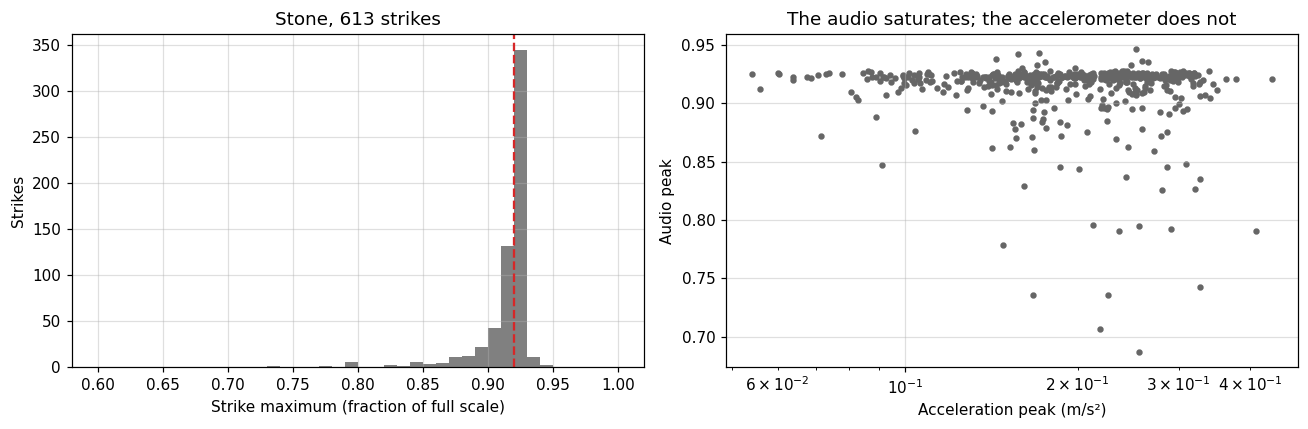

In [5]:
TZ = dt.timezone(dt.timedelta(hours=-5))
def t_wav(n):
    return dt.datetime(2025, 10, 19, int(n[9:11]), int(n[11:13]), int(n[13:15]), tzinfo=TZ).timestamp()
g = pd.read_csv(C.INTERMEDIATE / "strikes_with_acceleration.csv"); rows = []
for w, gw in g.groupby("file"):
    _, x = wavfile.read(C.AUDIO / w); x = x[:, 0].astype(float) / 32768
    for r in gw.itertuples():
        i = int((r.t_abs - t_wav(w)) * FS)
        rows.append({"zone": r.zone, "strike": r.strike, "peak": np.abs(x[i - 2400:i + 2400]).max(), "acc_peak": r.acc_peak})
pk = pd.DataFrame(rows); pk.to_csv(C.TABLES / "t09_stone_peaks.csv", index=False)
print(f"Peak of the {len(pk)} strikes: median {pk.peak.median():.3f}, maximum {pk.peak.max():.3f}; ≥ 0.90 of full scale: "
      f"{(pk.peak >= 0.90).sum()} ({(pk.peak >= 0.90).mean():.0%})")
dg = pd.read_csv(C.TABLES / "t03_damping_strikes.csv"); dg = dg[dg.valid].merge(pk, on=["zone", "strike"])
dg["limited"] = dg.peak >= 0.90; dg["Q_rel"] = dg.Q / dg.groupby("mode").Q.transform("median")
print(f"Q relative to the median of the mode ({len(dg)} fits):", dg.groupby("limited").Q_rel.median().round(3).to_dict(),
      f"Mann–Whitney p = {stats.mannwhitneyu(dg[dg.limited].Q_rel, dg[~dg.limited].Q_rel).pvalue:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pk.peak, bins=np.arange(0.6, 1.001, 0.01), color="0.5"); ax[0].axvline(0.92, color="C3", ls="--")
ax[0].set_xlabel("Strike maximum (fraction of full scale)"); ax[0].set_ylabel("Strikes"); ax[0].set_title(f"Stone, {len(pk)} strikes")
ax[1].scatter(pk.acc_peak, pk.peak, s=10, color="0.4"); ax[1].set_xscale("log")
ax[1].set_xlabel("Acceleration peak (m/s²)"); ax[1].set_ylabel("Audio peak"); ax[1].set_title("The audio saturates; the accelerometer does not")
plt.tight_layout(); plt.savefig(C.FIGURES / "fig09a_limiter.png", dpi=150, bbox_inches="tight"); plt.show()

## 9.4 Conclusion

* **Frequency:** the error of the phone is smaller than the tolerance of the tuning forks (≤ 0.15 %); the modal
  frequencies of the stone are reliable at that level.
* **Decay:** the T60 of the bowl (7.7 s, Q ≈ 1240, R² 0.998) does not depend on the microphone distance (8.0 s at 5 cm,
  7.8 s at 20 cm; p = 0.44). The bowl strikes that reached the limiter give a somewhat longer T60 (7.9 against 7.3 s,
  p = 0.05); with only 6 unlimited strikes, which were also the first of each take, this difference is not conclusive.
  On the stone, which is what matters, the Q of limited and unlimited strikes does not differ (1.000 against 0.999 of
  the median of the mode; p = 0.52).
* **Limiter:** most strikes on the stone reached the iOS peak limiter (≈ 0.92–0.94 of full scale). The limiter
  compresses the first milliseconds of the strike, but **hardly changes the measured Q** (the fits start 50 ms after
  the maximum). It affects the audio peak level, which was therefore not used as a measure of force (the accelerometer
  was used), and to a lesser extent the spectral features of the first milliseconds.
* **Bell reference:** the main mode of the steel bowl has a Q similar to the lightly damped modes of the stone
  (Q ≈ 1000–1240): the stone rings with a damping comparable to that of a metallic resonator, although at higher
  frequencies, so its T60 is shorter.